# 사전과제 언어모델과 생성모델

# 1. NLP와 언어 모델
## 1. NLP natural language processing

### 자연어 처리란?
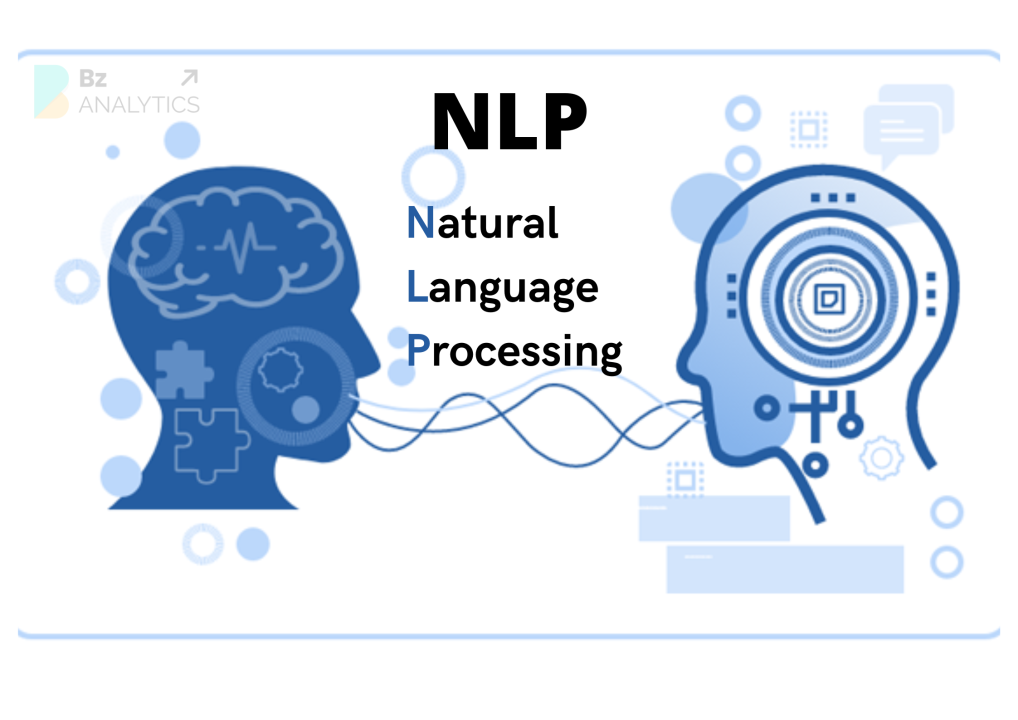 <br>
- 자연어 vs 프로그래밍 언어 :
     - 자연어 : 인간이 의사소통을 위해 사용하는 언어, 일대다 대응, 유연하지만 모호성이 높다
     - 프로그래밍 언어: 컴퓨터에 명령을 전달하기 위해서 설계된 언어, 일대일 대응, 상대적으로 명확하고 엄격하다.

- 자연어의 특징 :
     - 1. 이산적 데이터
          - 단어, 문자 등 구분된 기호로 구성되는 이산적 데이터
          - 연속적 숫자 데이터와 달리 컴퓨터가 직접 수학적으로 처리하기 어려움
          - NLP는 단어와 문장을 *숫자나 연속적 벡터로 변환(임베딩)* 해야함
     - 2. 순차적 데이터
          - 자연어는 단어가 등장하는 *순서에 따라* 문장의 의미가 변화
          - NLP는 단어의 *순서와 앞뒤 문맥을 함께 고려*해 처리할 수 있는 모델 구조 (RNN, Transformer 등)가 필요
     - 3. 중의성과 모호성
          - 하나의 단어나 문장이 *여러 의미로 해석*
          - NLP는 *문맥 전체를 파악*해서 적절한 의미 판단해야함.
     - 4. 희소성
          - 자연어는 단어의 종류와 조합이 다양해서 모든 표현 학습이 어려움
          - NLP는 *학습하지 않은 표현*도 단어 간 유사도를 이용해서 *확률적으로 추론*할 수 있는 능력 필요
     - 5. 가변성과 진화
          - 자연어는 지속적으로 변화
          - 언어 사용 방식도 변화 (신조어 줄임말 새로운 표현 등)
          - NLP는 *변화하는 언어랑 새로운 표현을 유연하게 패턴을 학습*하는 머신러닝 방식이 필요함
- NLP (자연어 처리)의 개념
     - 자연어를 *컴퓨터가 분석하고 이해하며 생성할 수 있도록 하는 인공지능의 기술* -> 언어를 *숫자/벡터 형태로 변환*하고 단어 간 관계와 문맥을 분석
     - 기계번역,감정분석,텍스트분석,문서요약, 질의응답 및 챗봇 등에 사용
- NLP의 역할
     - 1. 형태소 분석 : 문장을 (의미를 가진 가장 작은 단위) 형태소로 나누고, 각 형태소의 품사와 문법적 특징을 분석
     - 2. 구문 분석 : 문장의 문법적 구조를 분석 -> 단어 간 관계 파악
     - 3. 의미 분석 : 단어와 문장의 의미를 분석해서 문맥에 맞는 의미를 파악
     - 4. 담화 분석 : 여러 문장 사이의 연결 관계와 전체 대화 맥락을 분석하고 의미 파악

## 2. 언어모델
- 언어 모델의 정의
     - 대량의 텍스트 데이터를 학습해서 단어, 토큰의 *등장 확률을 예측* 하고 *문장의 자연스러움*을 판단하는 모델 = **인간이 말하고 쓰는 방식을 모방하는 시스템**
     - 앞 단어와 문맥으로 -> 다음 단어의 가능성 예측
     - 문장 구성 단어들의 등장 확률 계산 -> 문장 전체의 자연스러움 평가
     - 일반적으로... 확률 높은 문장 = 자연스러운 문장
     - *학습 방식*에 따라서 **통계적 언어 모델** 과 **신경망 언어 모델**로 구분된다.

# 2. 통계적 언어 모델 (SLM)
## 1. statistical language model
- *분포 가설* 에 근거
     - 뜻 : 비슷한 문맥에서 등장 = 서로 유사한 의미
     - 단어의 의미는 해당 단어가 어떤 단어들과 함께 등장하는지를 통해 파악 가능
     - 이후에 *임베딩 기술*의 이론적 기반
     - **조건부확률** : 특정 사건이 발생했을 때, 다른 사건이 발생할 확률
          - 앞에 등장한 단어를 조건으로 다음 단어가 등장할 확률
     - **카운트기반 확률** : 특정 문맥 이후에 어떤 단어가 얼마나 자주 나왔는지
          - 등장 빈도 높을수록 높은 확률
          - 한계 : *희소 문제* = 가능한 단어 조합이 많아서 *특정 표현이 학습 데이터에 거의 또는 전혀 등장하지 않는 문제*
               - 단어의 등장 빈도에 의존, 한 번도 등장 안하는 단어 조합 = 확률 0으로 계산
               - => 자연스러운 표현이더라도 학습 데이터가 없으면 적절한 확률을 부여하지 못함
               - **희소 문제 완화를 위한 확률 추정 기법과 새 언어 모델이 필요**

## 2. N-gram
- N-gram의 배경
     - SLM은 이전 단어들을 바탕으로 다음 단어 확률 계산하나,,, *문장이 길어질수록 한계가 발생*
          - **데이터 희소성** : 고려할 단어 조합이 증가하면서 학습 데이터에 *등장하지 않는 조합이 많아짐*
          - **계산의 복잡성** : 이전 모든 단어를 고려할 때 *확률을 계산하고 저장하는 데 많은 자원이 필요*
          - 이를 완화하기 위해서 NGRAM 등장!
- 정의 
     - **직전 n-1개의 단어를 바탕으로 다음 단어의 등장 확률 예측**
     - n이 커질수록 더 긴 문맥을 반영

- SLM과의 공통점과 차이점
     - 공통점
          - 등장 빈도와 조건부 확률로 다음 단어 예측
          - 학습 데이터에서 관측된 단어 조합으로 문장의 등장 확률과 자연스러움 평가
     - 차이점
          - SLM : 이전 등장한 모든 단어를 조건으로 다음 단어 확률 표현 가능, 긴 문맥 추정 어려움
          - N gram : 직전 N-1개의 단어만 고려해서 확률 계산 -> **계산과 확률 추정의 단순화**

- 한계
     - 1. 희소 문제
          - N값이 커질수록 단어 조합 수 증가 -> 훈련 데이터에서 *특정 단어 조합 찾기 어려워짐*
          - 학습데이터에 등장하지 않는 N-gram은 확률이 0으로
          - => 긴 문맥 반영 위하 N 값을 높이면 충분한 학습 데이터가 필요
     - 2. 문맥 제한
          - N-1개의 단어만 고려하기에 *멀리 떨어진 단어 사이의 관계 파악이 어려움*
          - 문장이 길어질 수록 *앞부분의 주요 정보가 예측 과정에서 제외*될 수 있다.
     
## 3. Perplexity (PPL)
- 정의
     - *얼마나 혼란스러워하는지*를 수치로 나타낸 지표
     - PPL이 낮을수록 : 모델의 예측 불확실성이 낮아서 실제 등장 단어를 *잘 예측*
- 특징
     - **문장 W의 빈도수와 PPL의 관계**
          - 문장 W가 훈련 데이터에 희소하게 등장할 수록 학습 기회가 적어져서 예측에 어려움 겪음 (PPL이 높음)
     - **단어 개수 N과 PPL의 관계**
          - *문장에 예측하기 쉬운 단어가 추가*되면 예측 난이도 감소로 *PPL이 감소*
          - N이 증가한다고 반드시 PPl이 낮아지는 것은 아니다!! -> 추가된 단어의 예측 난이도에 따라 달라짐

# 3. 신경망 언어 모델 (NLM)
- NLM의 등장
     - SLM의 한계를 완화하기 위해서 *인공 신경망을 활용하여 단어의 의미와 문맥을 학습하는 NLM, 신경망 언어모델의 등장*
          - 임베딩해서 단어 간 의미적 관계 학습
          - 신경망을 통해 단어 조합을 다양하게 찾고, 관측되지 않은 표현에도 일반화 할 수 있게 설계
          - 등장 빈도 + *단어 간 관계와 문맥 반영* => 다음 단어 예측

- 키워드 = **임베딩** <br> 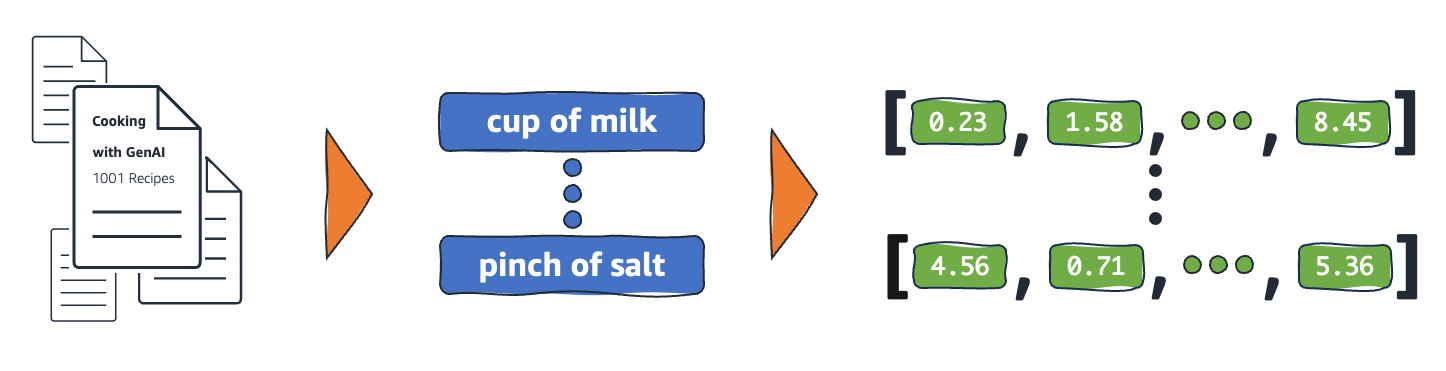 <br>
- 단어와 같은 이산적 언어 데이터를 *연속적 숫자 벡터*로 변환해서 단어 간 의미적 관계 기술
- NLM은 단어를 *고차원 벡터 공간 한 점으로 표현*하고 비슷한 단어들은 *벡터 공간에서 서로 가까운 위치에 놓이도록*
- => 이를 통해 **의미적 유사성 파악**, 학습 데이터에 등장하지 않은 표현이더라도 **일반화**


|구분|SLM|NLM|
|---|---|---|
|학습방식| 단어 등장 빈도, 확률 계산| 인공 신경망의 가중치 학습|
|단어 표현| 단어를 개별 기호로 취급 | 단어를 연속적 벡터로 표현|
|의미적 관계 | 유사 단어 간 관계 반영이 어려움 | **임베딩으로 의미적 유사성 학습** |
| 희소 문제 | 관측되지 않은 조합에 취약함  |**학습된 표현으로 희소 문제를 완화** |
| 문맥 처리 | Ngram 은 N-1개 단어만 고려 | **신경망 구조에 따라 다양한 범위 문맥 학습 가능** |
| 계산 비용 | 상대적으로 낮음 | 학습에 많은 연산 자원 필요|




# 4. 딥러닝 기반 언어 모델
## 1. Transformer 등장
- RNN, LSTM의 한계
     - 1. 장기의존성 문제
     - 2. 기울기 소실 문제
     - 3. 순차 처리의 비효율성
- Transformer 등장
     - self attention으로 단어 간 관계와 장거리 문맥 효과적으로 학습
     - 병렬 처리와 위치 인코딩으로 학습 효율 높이고 단어의 순서 정보 반영
     - BERT GPT 등 현대 언어 모델의 기반
- Transformer 구조 <br>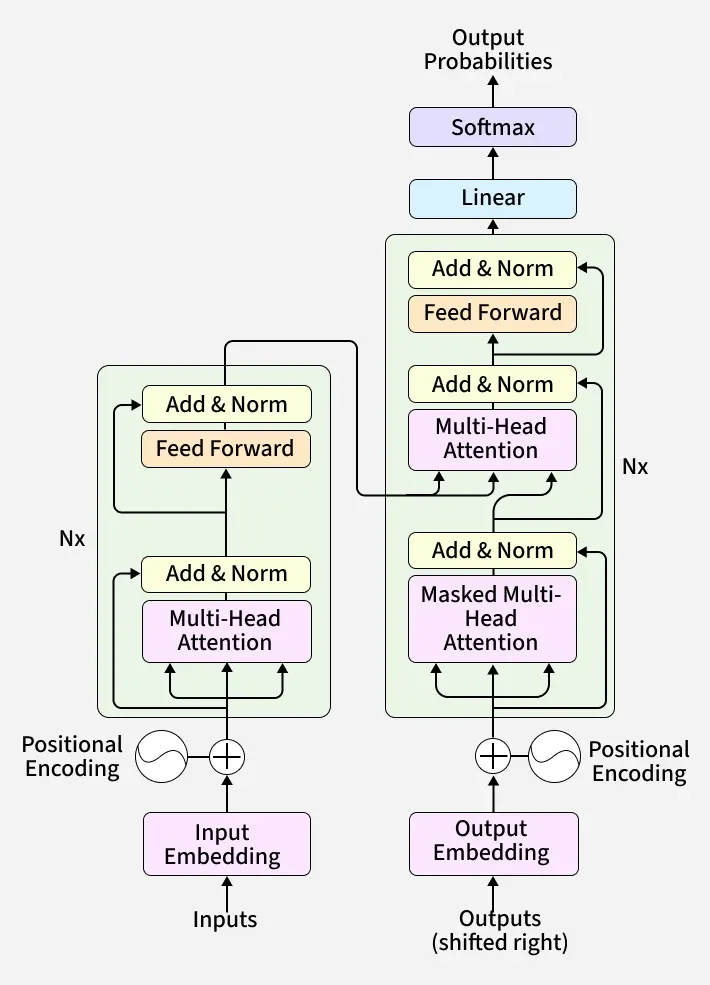 <br>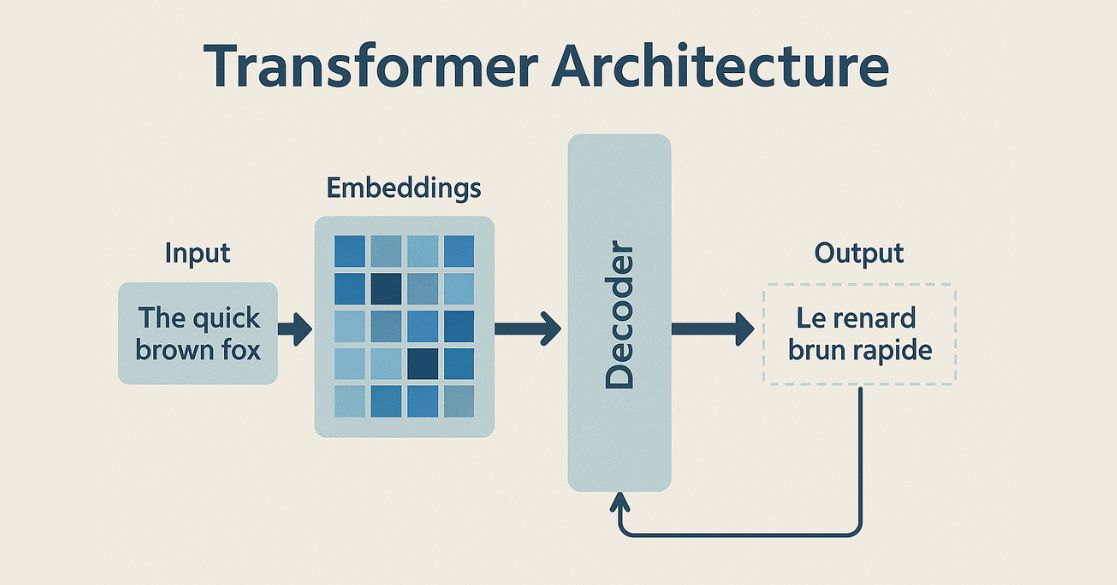<br>
     - 임베딩 및 위치 인코딩
          - 입력 문장 -> 토큰 단위 -> 벡터 변환
          - RNN과 달리 순환 구조가 없어서 위치 정보를 추가하여 단어의 순서 구분
     - 인코더
          - self attention :문장 내 단어들이 다른 단어들과 얼마나 관련되어 있는지 계산해서 문맥 파악
          - Feed Forward Network : attention 을 통해 얻은 정보 -> 신경망으로 변환해서 더 풍부한 특징 학습
          - 여러 층 인코더를 깊게 쌓아서 입력 문장 의미와 문맥 정교하게 학습
     - 디코더
          - masked self attention : 미래 단어를 보지 않고, 이전에 생성된 단어들만 참고해서 다음 단어 예측
          - cross attention : 인코더에서 전달 받은 정보를 참고해서 입력 문장과 출력 문장 사이의 관계 학습 
          - Feed Forward Network : attention 결과를 추가로 변환해서 다음 단어 예측에 활용
          - 여러 층의 디코더를 쌓아 -> 정보 처리 -> 단어 순차적 생성

## 2. BERT
- 정의
     - 인코더 구조를 기반으로 *문장의 양방향 문맥*을 학습해서 언어의 의미 이해하는 신경망 언어 모델
          - B : bidirectional (양방향학습)
          - ER : Encoder Representation (인코더를 활용해서 문맥이 반영된 단어 벡터 형성)
          - T : from Transformers (Transformer 인코더 구조 기반으로 설계된 모델)

- 특징
     - 양방향 : 앞에 등장 + 뒤에 등장한 단어를 고려해서 단어 의미 파악
     - 트랜스포머 기반 : 인코더 구조만 활용해서 문장 내 단어 간 관계 분석 (self attention)
     - 사전학습 + 파인 튜닝 :
          - 사전학습 : 대량의 텍스트 데이터 활용해서 언어의 일반적 구조와 문맥 학습
          - 파인튜닝 : 사전학습된 모델 + 추가학습 => 목적에 맞게 활용
- 학습 방법
     - 입력 문장의 토큰화 : 입력 문장을 토큰으로 분리 + 시작[CLS], 끝 [SEP]
     - 임베딩 : 각 토큰을 벡터로 변환, 토큰의 의미/위치/문장 구분 정보를 반영해서 입력 표현 생성
     - transformer encoder로 문맥 학습 : self attention, 여러 인코더를 거치며 문맥 반영된 벡터 표현 생성
     - 출력 및 활용 : 학습된 문맥으로 문장 이해를 목적으로 하는 작업 , 사전학습 하고 파인 튜닝하여 활용

- 사전학습 : NLP 작업 전, 대량의 텍스트 데이터로 언어의 일반적 구조와 문맥 미리 학습하는 과정
     - BERT는 텍스트 자체를 활용해서 학습
     - 사전학습으로 일반적인 언어의 특징 익힘 => 특정 작업에 맞게 파인튜닝
     - MLM과 NSP 두 가지의 학습 방법
- 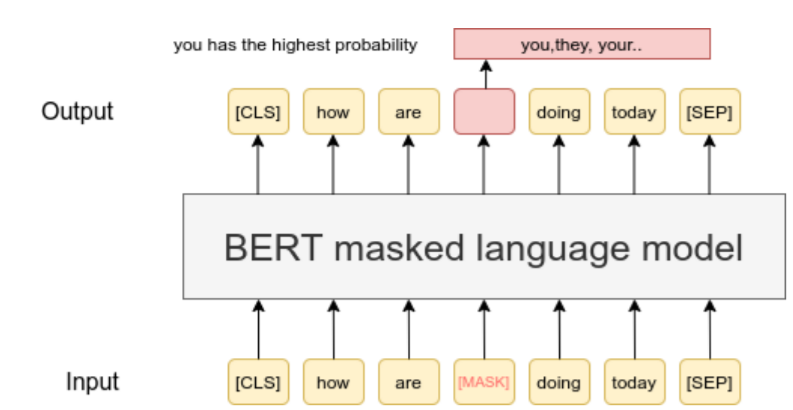 <br>
   - **Masked Language Model (MLM)** : 빈칸 채우기 방식 / 가려진 원래 토큰 예측하도록 학습시킴
     - 1. 입력 문장에서 일부 토큰 무작위 선택
     - 2. 선택된 토큰의 대부분을 [MASK]로 대체
     - 3. BERT가 가려진 토큰의 앞뒤 문맥을 함께 분석
     - 4. 원래 토큰을 예측하고 정답과 비교해서 모델 학습
   - 학습 효과 
     - 양방향 문맥 이해 능력 향상
     - 동일 단어라도 문맥에 따라 달라지는 의미 학습

   - **Next Sentence Prediction (NSP)** : 두 문장이 주어진다면, 두 번째 문장이 첫 번째 문장 바로 다음에 등장하는 문장인지 예측하도록 학습하는 방법
     - 1. 두 문장 A, B 입력
     - 2. B 실제로 A 다음에 오는 문장인지 판단
     - 3. 실제 그렇다면 IsNext, 무작위로 선택된 문장이면 NotNext
     - 4. 예측 결과랑 정답을 비교해서 모델 학습
   - 학습 효과
     - 두 문장 사이의 연결 관계와 문맥적 연관성 학습

## 3. GPT
- 정의 : transformer의 *디코더 기반 구조*를 활용해서 이전 단어를 바탕으로 다음 단어 예측하고 텍스트 생성하는 언어 모델
- 초기 지피티의 구조 : 디코더 기반 + masked self attention + feed forward network = 이전 토큰을 바탕으로 다음 토큰을 순차적으로 예측하는 *자기 회귀 방식으로 텍스트 생성*
- 최근 지피티 : 지시와 예시만으로 다양한 작업을 수행하는 *In Context Learning* 능력을 보여줌

## 4. LLM (large language model)
- 방대한 텍스트 데이터 + 대규모 신경망 => 인간의 언어 이해하고 생성하도록 학습된 인공지능 모델

- 작동 방식 
     - **학습** : 단어와 단어 사이 관계, 의미, 문법, 세상의 지식까지 언어의 패턴을 *스스로 터득*
          - 사전 학습 = 대량의 텍스트 데이터 => 다음 토큰 예측하는 작업 반복, 언어의 구조와 문맥 학습
          - 파인 튜닝 = 사전학습된 모델 + 추가학습 => 목적에 맞게 활용
          - 예측값과 정답 차이 계산하고 가중치 업데이트

     - **예측**
          - 입력 처리 -> 문맥 분석 -> 다음 토큰 예측 -> 결과 생성 

- LLM이 GPT 방식을 사용하게 된 이유 
     - BERT = 양방향 문맥 활용으로 입력 문장 이해에 중점
     - GPT = 이전 토큰으로 다음 토큰 순차적 예측해서 텍스트를 생성하는 데에 특화
     - => 사용자의 질문에 대해 새로운 문장 생성해야하는 LLM은 GPT 계열 구조가 사용되기 시작

- 한계 
     - 환각 : LLM이 그럴듯한, 사실과 다른 정보를 그럴 듯하게 생성하는 현상, 사실 여부가 보장 안됨
     - 높은 학습 및 업데이트 비용 : *대규모 데이터를 활용하는 사전학습* = 막대한 연산 자원과 시간 비용 필요, 추가학습 진행에도 비용 발생


## 5. RAG
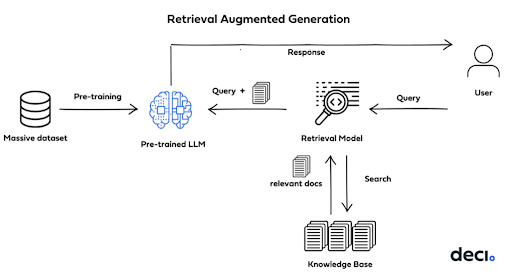 <br>
- 외부 지식 검색과 LLM 텍스트 생성 능력을 결합해서 *답변의 정확성과 최신성*을 높이는 기술 = **외부 정보를 검색해서 답변 생성에 활용하는 RAG 기술 등장
      - 질의 인코더 : 질문-> 숫자 벡터로 변환, 관련성 높은 문서 검색
      - 지식 검색기 : vector DB에서 질문 벡터와 유사도 높은 문서 검색
      - 지식 증강 생성기 : 질문+ 검색된 외부 문서 -> LLM에 입력 -> LLM 이 최종 답변 생성
- 장점
      - 최신 정보 반영 : 모델을 재학습 하지 않고도 최신 문서 검색해서 활용
      - 정보 정확성 향상 : 검색된 외부 자료를 근거로 답변 생성, 환각 현상 완화
<br>
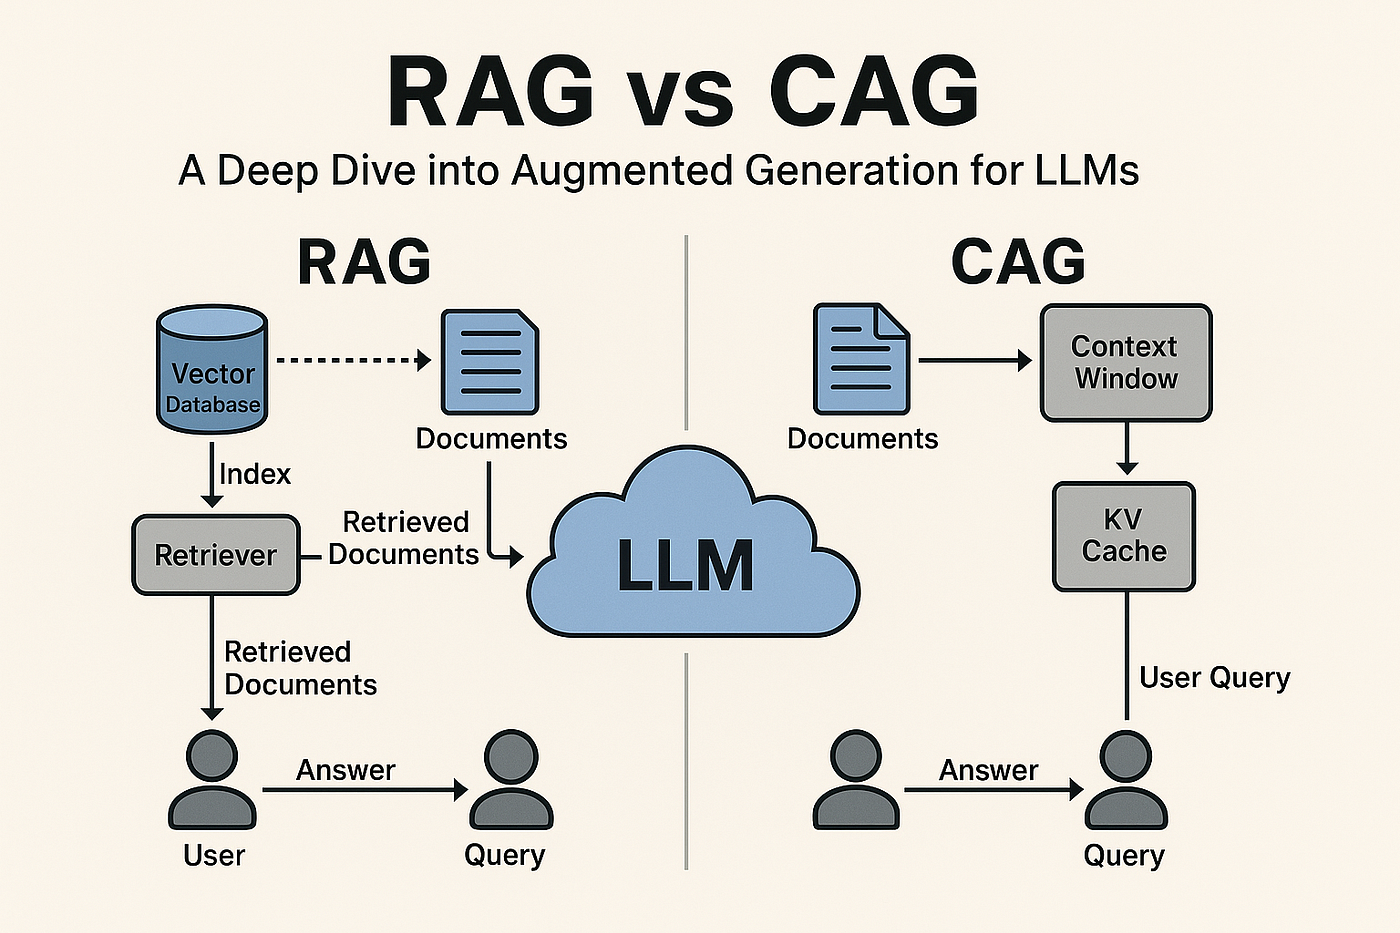
<br>
- CAG (credibility aware generation)
      - 모델이 신뢰도를 *스스로 판단하고 활용하도록 훈련*
      - RAG 의 한계 = 오래되거나 부정확한 정보의 가능성
      - CAG = 검색된 정보의 관련성만이 아니라 *출처의 신뢰성, 최신성 고려해서 답 생성* 
      - 구조 = 질문 입력 -> 정보 검색 -> 신뢰도 평가 -> 정보 선별 -> 최종 답변 생성

## 6. LangChain 
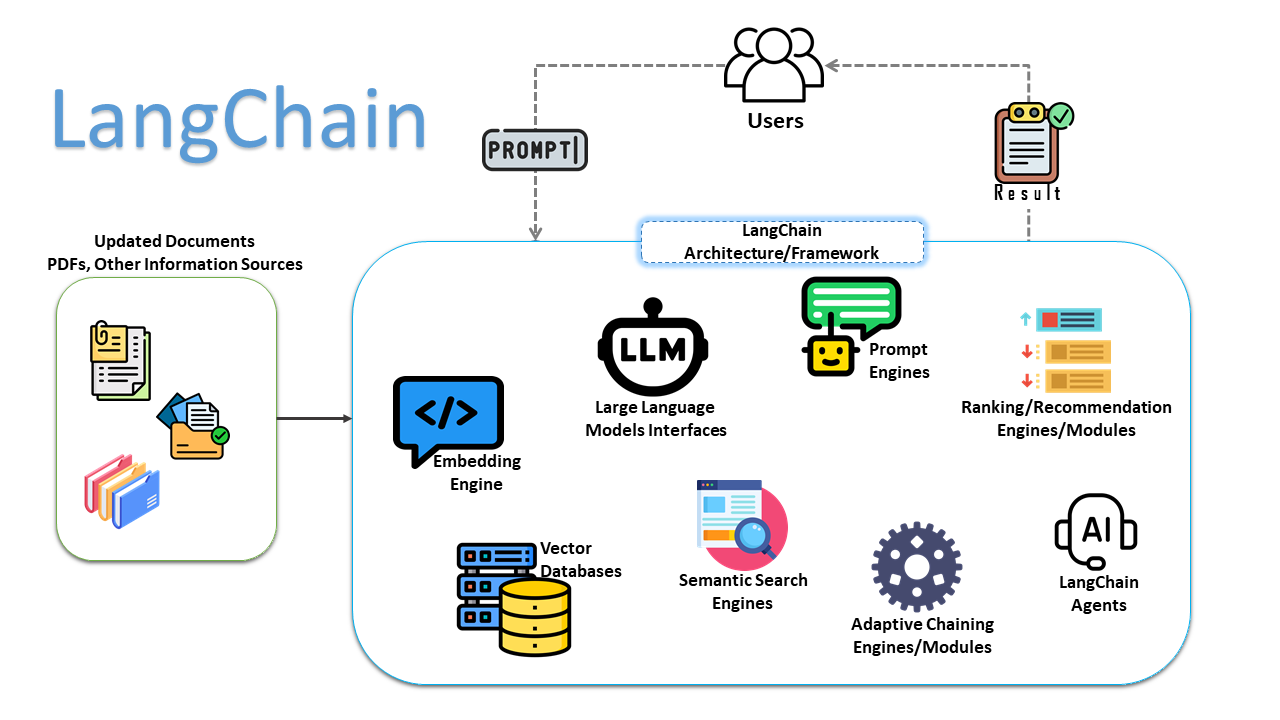
<br>

-  복잡한 AI를 쉽게 개발할 수 있게 지원하는 오픈소스 프레임워크
-  구현의 복잡성, 외부 시스템 연동, 유지 보수의 어려움 해결하기 위해 LangChain 등장!
- 특징
     - 추상화 :복잡한 기능 -> 간단한 인터페이스 
     - 표준화 : 서로 다른 LLM , 외부 도구 등을 일관된 방식으로 사용
     - 체이닝 : 여러 작업을 *순서대로 연결해서 하나의 작업 흐름*으로 구성
- 한계
     - 선형적 구조 (순차적)에 적합
     - 복잡한 AI 시스템은 실행 경로가 달라지거나 이전 단계로 돌아가 재실행해야 하는 상황이 발생 
     - => LangGraph로 해결! (조건부분기, 반복 실행, 상태 관리가 가능)

- **langGraph** <br> 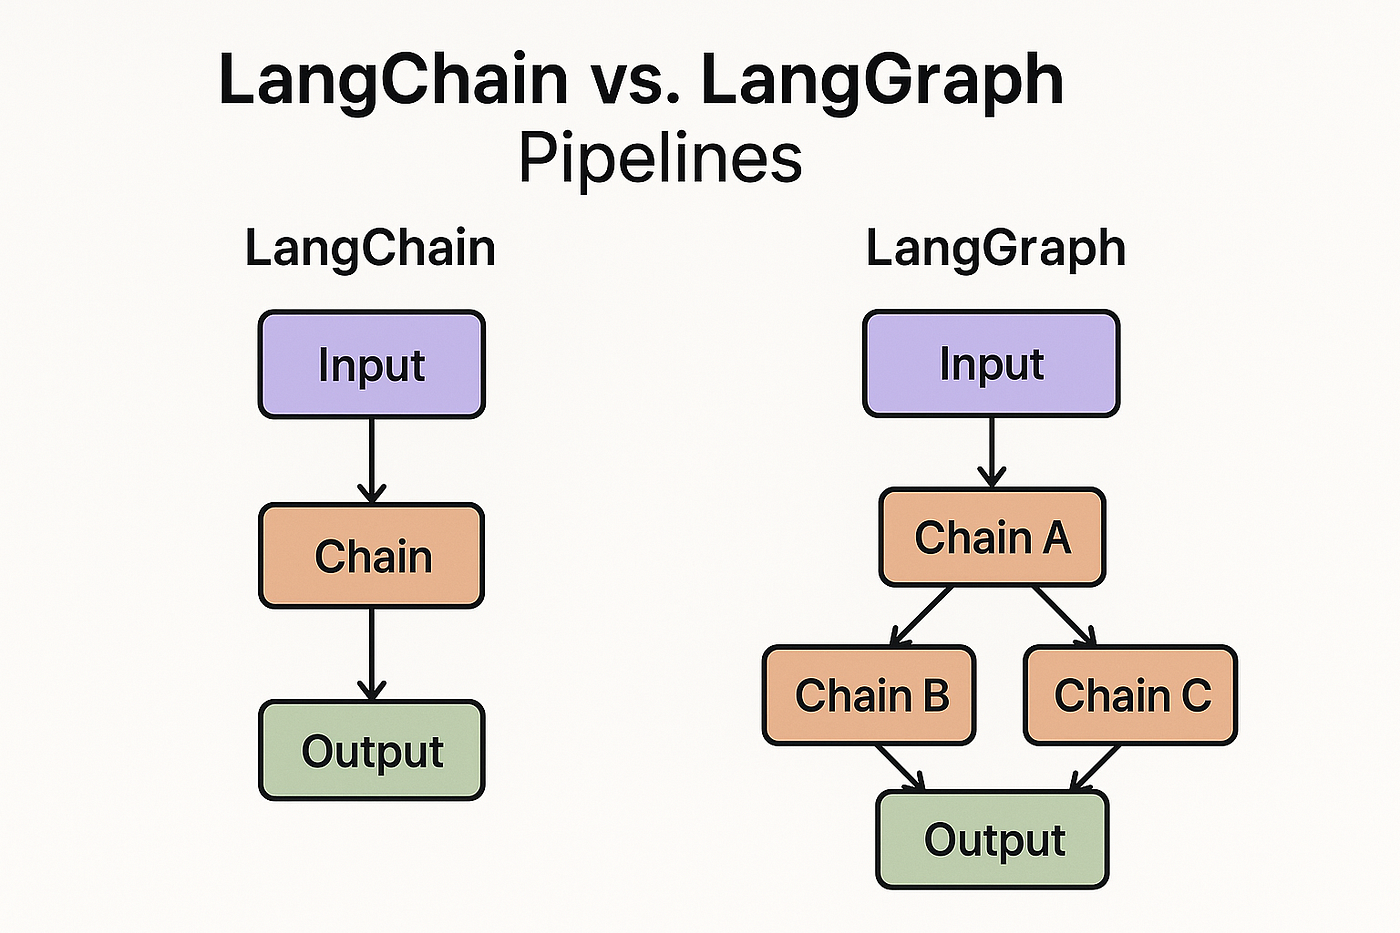 <br>
     - 노드와 엣지로 여러 작업 연결 -> 조건에 따른 분기와 반복이 가능한 AI workflow를 구현하는 프레임 워크
     - 노드 : LLM, Agent, tool
     - 엣지 : 노드 사이 연결 관계, 다음에 실행할 작업과 이동 경로 결정
     - 상태 : 노드 간 공유되는 정보 -> 이전 작업 결과와 대화 문맥 저장
     - **agent와 tool 유연하게 연결, 비선형적이고 동적인 작업 흐름 구현**

- **langsmith** 
     - 실행 과정 추적, 성능 평가, 운영 상태 모니터링 할 수 있도록 지원하는 개발 및 관리 플랫폼
     - 핵심 기능
          - 디버깅 및 추적 : 오류 원인 파악하고 문제 해결
          - 테스트 및 평가 : 모델의 정확성과 성능 평가 -> 개선 효과확인
          - 모니터링 : 모델의 응답 시간, 오류 발생률, 사용량 및 비용 모니터링해서 성능 저하 조기 발견 -> 운영 안정적 지원
          - 프롬프트 허브 : 프롬프트 개선을 지원

- API 활용법 : 내부 지식만을 이용해서 해결이 불가하면 외부 API와 연동해서 답변



# 5. sLM (small Language Model)
## 1. sLM?
- 소규모 언어 모델 = 자연어를 처리, 이해, 생성할 수 있는 AI 모델
- LLM보다 규모와 범위가 작은 모델, 메모리와 연산 자원을 덜 사용한다.
- 모바일 앱과 같은 환경에 적합하며, 오프라인 추론에도 활용한다 

## 2. 모델 압축 방법
- 모델의 주요 성능은 유지하면서 크기와 연산량 줄이는 기술
- 1. 가지치기 : 신경망에서 불 필요한 부분 제거 -> 모델을 가볍게 만드는 기술
- 2. 양자화 : 숫자의 표현 정밀도를 낮춰서 모델을 더 작고 효율적으로 만드는 기술
- 3. 저차원 분해 : 큰 행렬을 작은 행렬들의 곱으로 표현해서 파라미터를 효율적으로 사용
- 4. 지식 증류 : 큰 모델의 지식을 작은 모델에 전달해서, 적은 파라미터로도 좋은 성능을 내게 해준다.

## 3. 장점
- 1. 성능적 측면
     - 빠른 응답 속도 , 제한된 환경에서의 실행 (스마트폰 노트북), 보안 및 데이터 보호
- 2. 비용적 측면
     - 낮은 운영 비용, 적은 전력 소비, 하드웨어 비용 절감

### 4. 한계
- 모델 크기가 작고, 학습 정보에 제약이 있다
- 1. 편향된 답변 생성
- 2. 제한된 일반화 및 복잡한 작업에서 성능 저하 : 낮은 범용성과 추론 능력
- 3. 환각 현상 : 사실과 다른 정보 생성

### 5. LLM과 결합 : 결합 추론
- sLM과 LLM을 함께 활용해서 각 모델의 장점을 살리는 방식 <br>
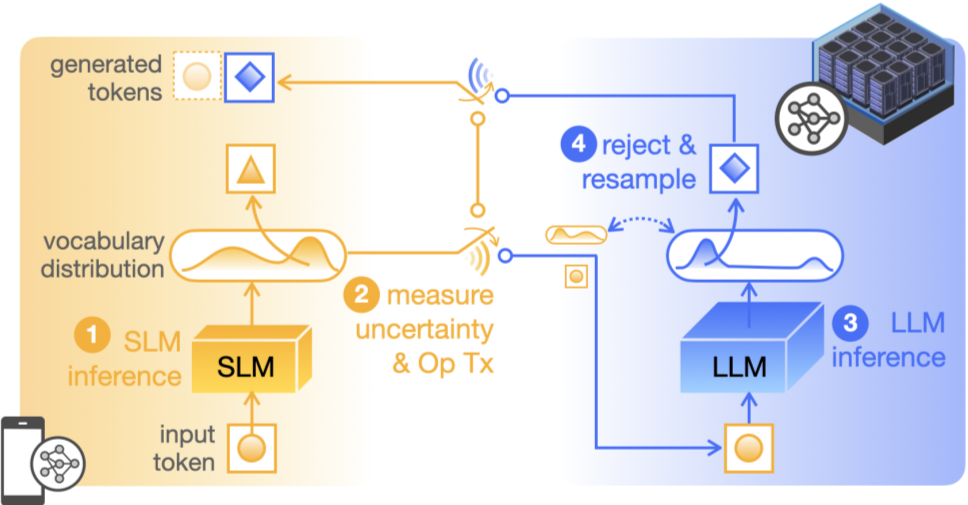 <br>
- 1. 간단한 작업은 sLM이 처리
- 2. 복잡한 작업은 LLM이 처리
- 3. 모든 작업을 LLM이 처리하지 않기 때문에 필요한 수준의 성능을 확보할 수 있다.
<br>
=> sLM의 효율성 + LLM의 높은 문제 해결 능력 결합!


# 6. 생성 모델의 개념

## 1. 분류모델 vs 생성모델

- 생성모델 : 주어진 학습 데이터를 학습 => 학습 데이터의 분포를 따르는 유사 데이터 생성
- 분류 모델과 생성 모델의 차이

|구분|분류모델|생성모델|
|---|---|---|
|학습방법|데이터 특징, 정답레이블 관계 학습 | 데이터 특징, 확률분포 학습|
|학습목표| X가 주어졌을 때 Y에 속할 확률 학습해서 분류 | X가 나타나는 확률분포 학습해서 데이터 생성|
| 주요특징| 데이터 차이점 학습해서 분류 기준 형성| 공통적 특징과 다양한 패턴 학습해서 입력 데이터의 적합성 평가, 비정상적 입력 탐지하는 데에 활용|
| 출력결과| 범주, 범주별 예측 확률 | 새로운 이미지 텍스트 음성|
|한계 | 처음 보는 이상한 데이터도 기존 데이터로 분류할 수 있음, 일반적 분류 모델은 새 데이터 생성 못함 | 부자연스러운 결과 나올수도, 생성 결과 품질 평가 어려움|

## 2. 생성 모델 분류
- 기준 ='데이터의 확률밀도를 직접 계산 가능?'
- 1. 명시적 확률밀도 모델 : 확률분포 명시적으로 정의해서, P(X)의 값을 직접적으로 수치화해서 출력
     - 1) 다루기 쉬운 밀도 모델 : 확률밀도 수학적으로 직접 계산 가능한 모델 
     - 2) 근사적 밀도 모델 :확률밀도 계산이 어려워서 근사적 방법을 활용하는 모델 
- 2. 암시적 확률밀도 모델 : 확률 밀도 직접 계산 안하고 학습한 분포에서 새 데이터 생성, 데이터가 가지는 특징과 패턴 학습
     - 1) 직접 샘플링 : 무작위 노이즈를 입력해서 새로운 데이터를 직접 생성하는 방식, 생성 모델 한 번 통과해서 결과 생성
     - 2) 간접, 반복적 샘플링 : 여러 단계의 확률적 상태 변화를 반복해서 새로운 데이터 생성, 여러 단계의 상태 변화를 거쳐서 학습한 데이터 분포 따르는 표본을 생성


# 7. AE, VAE

## 1. AE
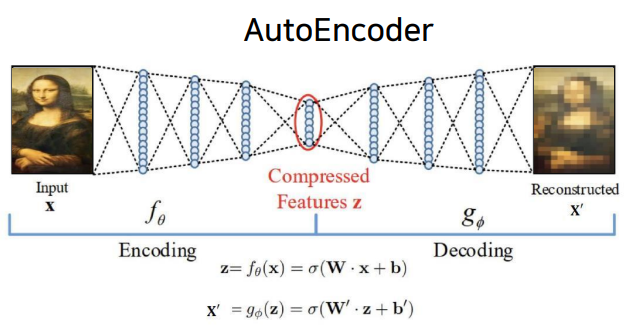 <br>
- AE = 입력 데이터의 주요 특징 압축, 이를 바탕으로 원래 데이터와 최대한 유사하게 복원하도록 학습하는 인공신경망 모델
     - 데이터의 핵심적 특징 학습, 입력 데이터와 복원 데이터 차이 최소화가 목표
     - 기존 인코더 디코더 = 입력 데이터 이해하고 이를 바탕으로 결과 생성
     - AE의 인코더 디코더 = 입력 데이터 특징을 압축하고 원래 데이터로 복원
- 핵심 : AE는 *입력 데이터 자체를 복원하는 것이 핵심*
<br>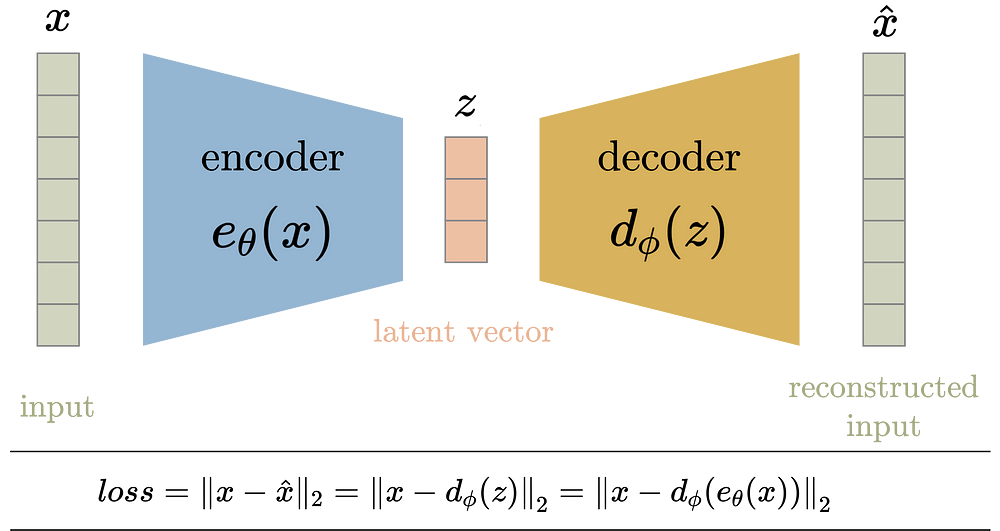 <br>
- 압축 단계 : 주요 특징 추출, 정보 압축
- 병목 통과 : 인코더가 추출한 핵심 정보 -> 잠재벡터로 표현, 데이터 핵심적 특징 학습하도록 유도
- 복원 단계 : 압축된 잠재 벡터를 활용해서 원본 데이터와 유사한 데이터 복원 , 얼마나 주요 정보가 잘 보존되었는지 확인

- ? 왜 압축했다가 복원 ?
     - 1. 왜 압축? : 그대로 전달하면 입력 데이터를 단순히 복사하는 방식으로 복원, 하지만 모델은 **어떤 정보가 원복 복원에 가장 중요한지 학습** 해야함.
     - 2. 왜 복원? : 압축 정보 만으로 원본과 유사한 데이터 만들 수 있는지 확인해야함. 복원 오차를 줄이도록 학습
     - 3. 결과적으로 무엇을 학습? : 데이터의 핵심적 특징과 구조 학습

- 한계
     - 잠재공간의 빈 영역 -> 입력 데이터를 최대한 정확하게 복원하는 것 주요 목표.
     - 기존 데이터 복원에는 효과적이지만 임의의 잠재 벡터를 이용해서 새 데이터를 안정적으로 생성하는 데에 한계 존재

## 2. VAE
- 등장 배경 = AE의 한계 잠재 공간이 불규칙하게 형성될 수 있어 잠재 공간에서 임의의 값 선택하더라도 자연스러운 데이터 생성 어렵다는 한계 존재. => VAE는 **데이터를 확률 분포로 표현해서 규칙적으로 잠재 공간 구성하도록 학습**

- 정의 : 입력 데이터 특징을 확률 분포로 학습, 해당 분포에서 샘플링하여 새 데이터를 생성할 수 있는 생성 모델
     - 기존 인코더, 디코더 구조 기반
     - 데이터 확률적 특성으로 새로운 데이터 생성 가능
     - 변분 추론으로 복잡한 확률분포를 근사적으로 학습

- AE 한계 개선 
     - 가우시안분포 형태로 데이터 특징 학습 -> 잠재공간 일정한 분포 따르도록
     - 잠재공간에서 값을 샘플링해서 기존 학습 데이터와 유사한 *새로운 데이터 생성*

- 학습 목표
     - 1. 복원 오차 최소화
          - 원본의 특징을 최대한 잘 복원하도록 학습한다
     - 2. KL 발산 최소화
          - KL 발산 = 두 확률 분포가 얼마나 다른지 수치로 표현
          - 인코더가 예측한 잠재분포가 *표준정규분포*에 가까워지도록..
          - 잠재공간의 불규칙한 형성 문제 완화, 새 데이터 생성하기 좋은 잠재 공간 형성하도록 유도

- 활용 분야 : 이미지 생성, 데이터 증강, 이상 탐지, 특징 추출

-  AE가 입력 **데이터의 압축과 복원**에 집중한다면, VAE는 확률분포를 학습하여 **새로운 데이터까지 생성할 수 있도록 발전한 모델**이라고 할 수 있다.

- AE와 VAE의 차이 = **입력 데이터의 특징을 잠재 공간에 어떤 형태로 배치하도록 학습?**
     - AE  : 입력 데이터를 하나의 고정된 잠재 벡터로.. -> 잠재 공간에 데이터가 불규칙하게 배치
     - VAE : 입력 데이터를 확률 분포로... -> 잠재 공간이 일정한 분포를 따르도록 학습해서 새 데이터 생성하기 쉽게 만든다.
    
     - 잠재공간 : 입력 데이터에서 추출한 핵심적 특징을 숫자 벡터로 표현하는 공간
          - 비슷한 특징 -> 가까운 위치
          - AE의 잠재 공간 : 하나의 고정된 잠재 벡터. 동일 데이터 = 동일 잠재 벡터
          - 비교 : AE는 잠재 벡터들이 불규칙적이며 데이터 사이의 빈 영역이 발생한다. 반면 VAE는 일정한 확률 분포에 가까워지도록 학습되어서 데이터 사이 공간에서도 *새로운 잠재 벡터 샘플링이 쉽다*
          <br>

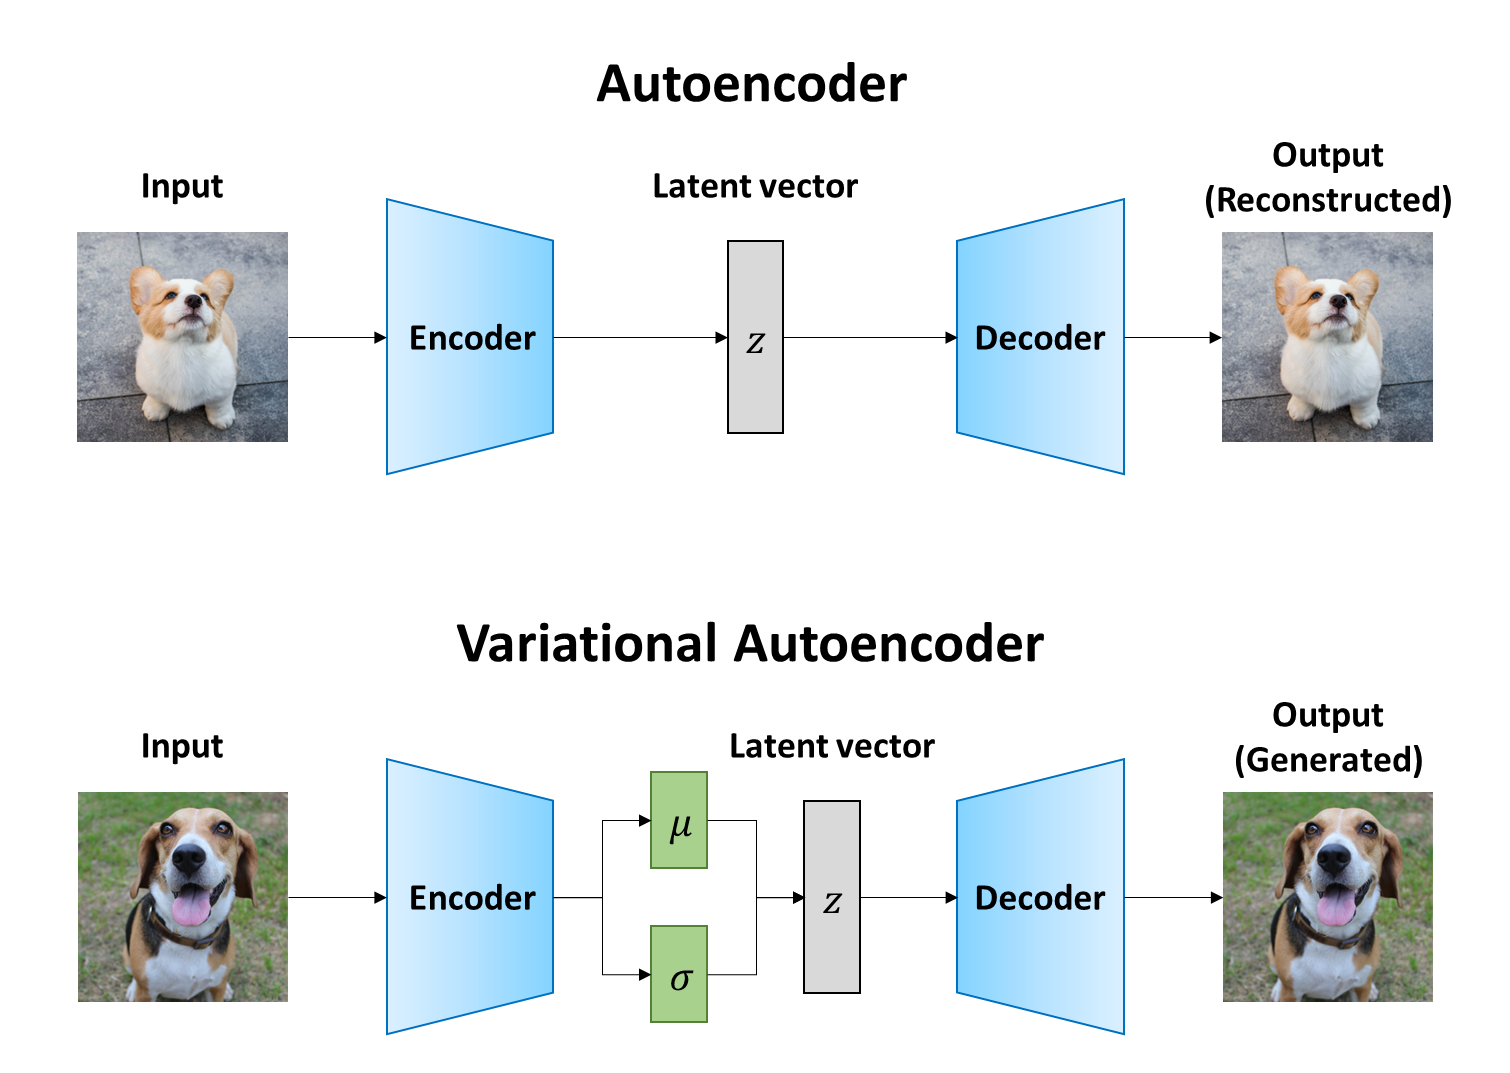 <br>

- VAE의 구조와 작동 과정 : 분포 예측 -> 샘플화 및 재파라미터화 -> 생성
     - 1. 분포 예측 단계
          - 입력 데이터 특징을 분석 -> 확률 분포를 예측
          - 입력 데이터 => 확률적 인코더로 => 평균과 표준편차 예측
          - 왜 확률분포 예측? : 기존 데이터 유지하면서도 조금씩 다른 새로운 데이터 생성
     - 2. 샘플링 및 재파라미터화 
          - 예측한 확률분포에서 잠재 벡터를 추출하는 단계
          - 예측한 확률분포에서 잠재 벡터를 무작위로 샘플링
          - 재파라미터화란? : 무작위성 별도의 노이즈 변수로 분리하는 방법, 샘플링 과정에서도 신경망이 학습할 수 있도록 함.
     - 3. 생성 단계
          - 샘플링한 잠재 벡터를 이용해서 데이터를 복원하거나 새롭게 생성하는 단계
          - 샘플링한 잠재 벡터 -> 확률적 디코더에 전달 -> 데이터의 확률분포 예측하고 이미지 복원 또는 생성
          - 학습 과정에서는 원본과 복원 데이터가 최대한 유사해지도록 학습
          



# 8. GAN

## 1. GAN의 개녕

- GAN이란?
     - 생성자와 판별자라는 두 신경망이 경쟁하면서 *실제 데이터와 유사한 새로운 데이터를 생성하도록 학습하는 생성 모델*
     - 생성자= 진짜 같은 가짜 데이터 만듦. 판별자 = 입력된 데이터의 진위 판별 -> 서로 적대적인 생성 신경망
- 목적
     - 생성자 : 실제 데이터와 유사한 가짜 데이터 생성 -> 학습이 진행될수록 실제 데이터 특징을 더 잘 반영
     - 판별자 : 실제 데이터와 생성자가 만든 데이터를 최대한 정확하게 구별
     - 궁극적 목적 : 생성자가 실제 데이터의 분포 학습하도록 만든다. ->**실제 데이터와 구분이 어려운 , 자연스러운 새로운 데이터 생성**

- 구조 <br> 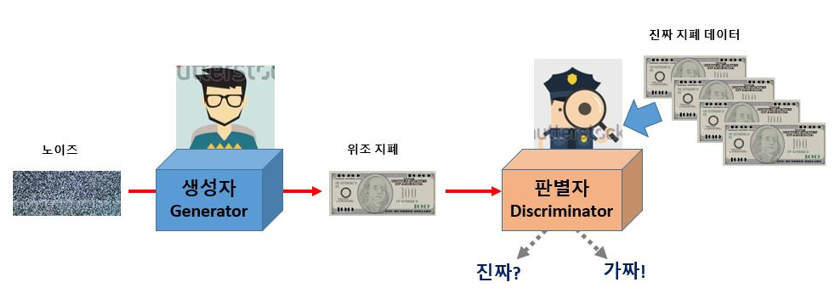 <br>
      - 생성자와 판별자는 서로 다른 목표를 가져 경쟁하는 구조 -> Minimax Game
      - 1) 무작위 노이즈 : 생성자에 입력되는 무작위 숫자 벡터
      - 2) 생성자 : 무작위 노이즈 입력 -> 생성된 가짜 이미지 출력
      - 3) 판별자 : 실제 이미지나 생성자가 만든 이미지 입력 -> 입력된 이미지가 진짜일 확률 출력
           - 실제 이미지는 높은 확률, 가짜 이미지는 낮은 확률 부여하도록
- 장단점
     - 장점
          - 1. 진짜 같은 가짜 생성 가능
          - 2. 높은 이미지 선명도
          - 3. 빠른 생성 속도
          - 4. 잠재 공간의 부드러움
    - 한계점
         - 1. 학습의 불안정성
         - 2. 훈련 초기 문제
         - 3. 모드 붕괴
         - 4. 평가 지표의 한계
         - 5. 역매핑의 어려움
- 사례 : 
     - nvidia 가상 인물 이미지 생성
     - deep video portraits 인물 영상 합성
     - facebook - eye in painting

# 9. 확산 모델
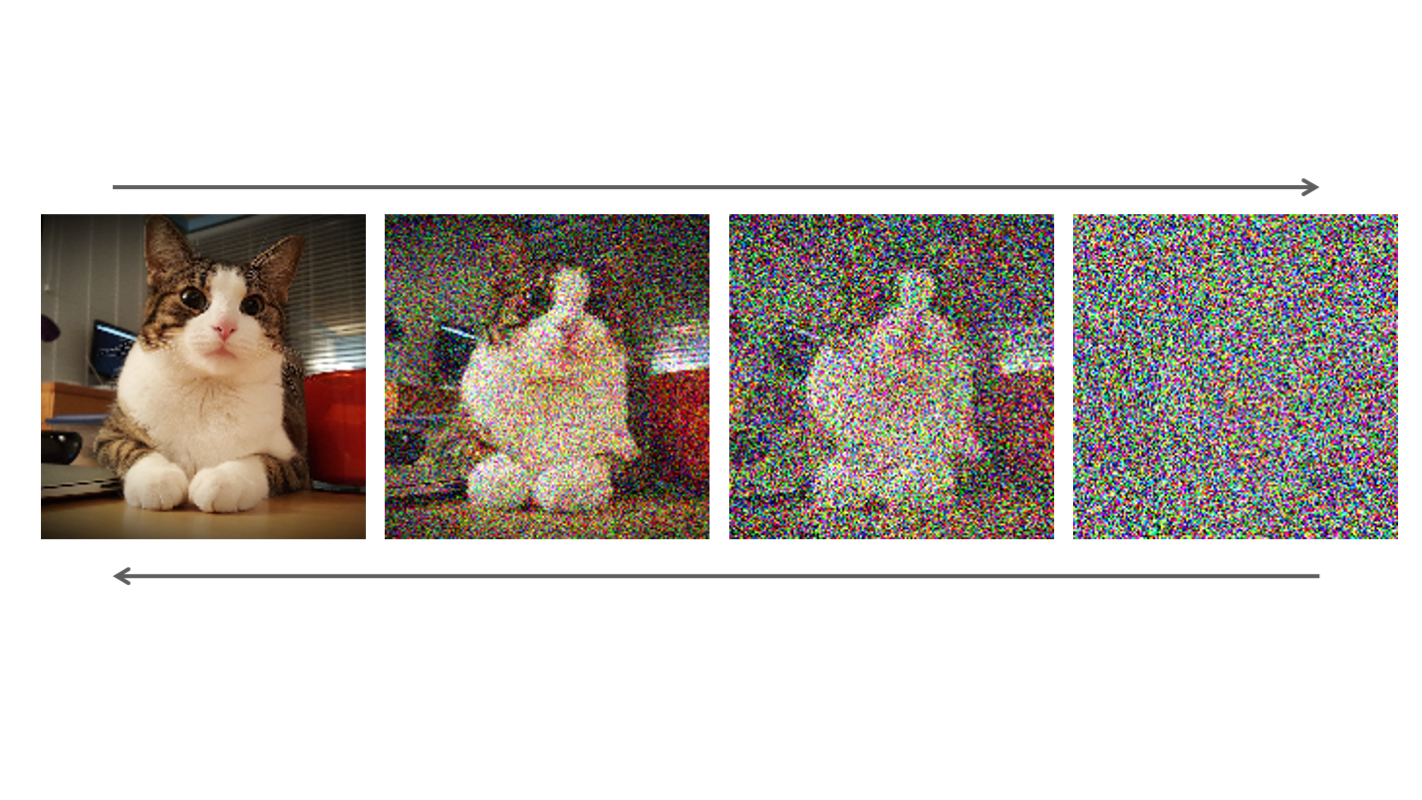

## 1. 확산 모델의 개념

- 정의 : 이미지+ 노이즈 데이터를 학습-> 무작위 노이즈를 점차 제거하면서 새 이미지를 생성하는 AI 모델

- 원리 : 실제 이미지에 노이즈 추가해서 이미지 흐트러지게 -> 노이즈 제거하는 방법 학습  -> 학습 완료되면 무작위 노이즈에서 시작해 새 이미지 만듦

- 핵심 과정 : 순확산, 역확산
- 활용분야 : 이미지 생성, 복원, 편집, 영상 생성 등

- 확산 모델의 목적
     - 목표 : 실제 데이터의 특징과 분포 학습, 새 데이터를 자연스럽고 다양하게 생성
     - **모호성 모델링** : 하나의 조건에서 여러 가지 결과가 가능하다는 불확실성을 확률적으로 표현

## 2. 확산 모델의 구조 
- 1. **순확산** : 원본 이미지에 가우시안 노이즈를 추가하면서 최종적으로 *무작위 노이즈에 가까운 상태로 만드는 과정*
     - 목표 : 다양한 수준의 노이즈 추가해서 이후 역확산 과정에서 노이즈 제거 방법을 학습할 수 있도록 하는 것
     - 과정 
          - 1. 원본이미지 , 노이즈 없이 깨끗
          - 2. 노이즈 추가 -> 점차 흐려짐
          - 3. 무작위 노이즈 -> 최종적으로 무작위 노이즈와 가까운 상태

- 2. **역확산** : 무작위 노이즈에서 시작해서 노이즈를 *단계적으로 제거하면서 새 이미지 생성하는 과정*
     - 목표 : 신경망이 학습한 노이즈 제거법을 활용해서 실제와 유사한 자연스러운 이미지 만드는 방법
     - 과정
          - 1. 무작위 노이즈
          - 2. 이미지 생성 -> denoising U net , 노이즈 조금씩 개선
          - 3. 새로운 이미지 생성

## 3. 장단점
- 장점 
     - 압도적 샘플 품질
     - 학습의 안정성
     - 다양성 확보
- 단점
     - 느린 생성 속도
     - 높은 계산 비용
     - 구조적 제약